In [1]:
import pandas as pd

In [4]:
# constants I want to keep

# DATA_DIR = Path('raw/')

## Big Basket Data

In [7]:
df_bigbasket = pd.read_csv("raw/bigbasket/bigbasket.csv")
df_bigbasket.head()

,ProductName,Brand,Price,DiscountPrice,Image_Url,Quantity,Category,SubCategory,Absolute_Url
0,Onion (Loose),Fresho,69.75,52.0,https://www.bigbasket.com/media/uploads/p/l/40...,2 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/40075537/fresho-o...
1,Onion,Fresho,174.35,130.0,https://www.bigbasket.com/media/uploads/p/l/12...,5 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/1201414/fresho-on...
2,Onion (Loose),Fresho,34.87,26.0,https://www.bigbasket.com/media/uploads/p/l/10...,1 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/10000148/fresho-o...
3,Onion,Fresho,69.74,52.0,https://www.bigbasket.com/media/uploads/p/l/12...,2 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/1201413/fresho-on...
4,Onion (Loose),Fresho,174.37,129.0,https://www.bigbasket.com/media/uploads/p/l/10...,5 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/10000150/fresho-o...


In [11]:
df_bigbasket["ProductName"].value_counts()

Tea                                                                                                                                  10
Extra Light Olive Oil                                                                                                                 9
Idli Rice                                                                                                                             8
Cashew/Godambi - Split                                                                                                                8
Purifying Neem Face Wash                                                                                                              8
                                                                                                                                     ..
Whiteglow Skin Whitening & Brightening Cleansing Milk                                                                                 1
Men Charcoal Face Scrub                         

<Axes: title={'center': 'Products by Count'}>

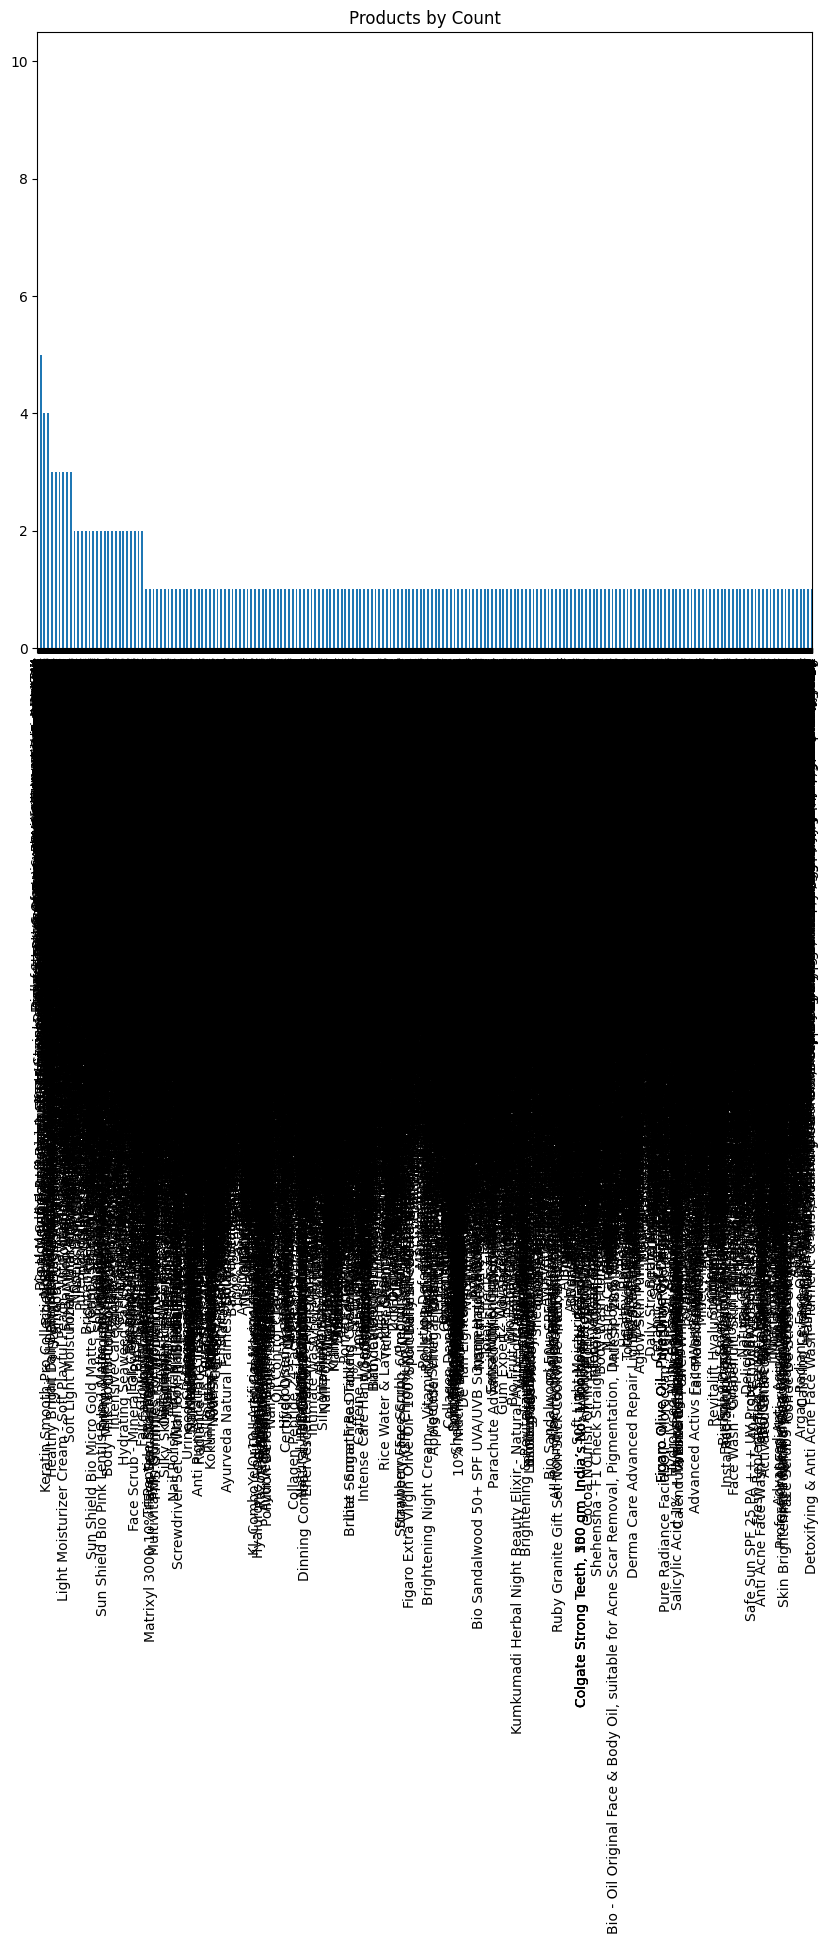

In [14]:
df_bigbasket["ProductName"].value_counts().plot(
    kind="bar", figsize=(10, 8), title="Products by Count"
)

In [18]:
df_bigbasket["ProductName"].value_counts(normalize=True)

Tea                                                                                                                                  0.001218
Extra Light Olive Oil                                                                                                                0.001096
Idli Rice                                                                                                                            0.000975
Cashew/Godambi - Split                                                                                                               0.000975
Purifying Neem Face Wash                                                                                                             0.000975
                                                                                                                                       ...   
Whiteglow Skin Whitening & Brightening Cleansing Milk                                                                                0.000122
Men Ch

<Axes: title={'center': 'Categories by Count'}>

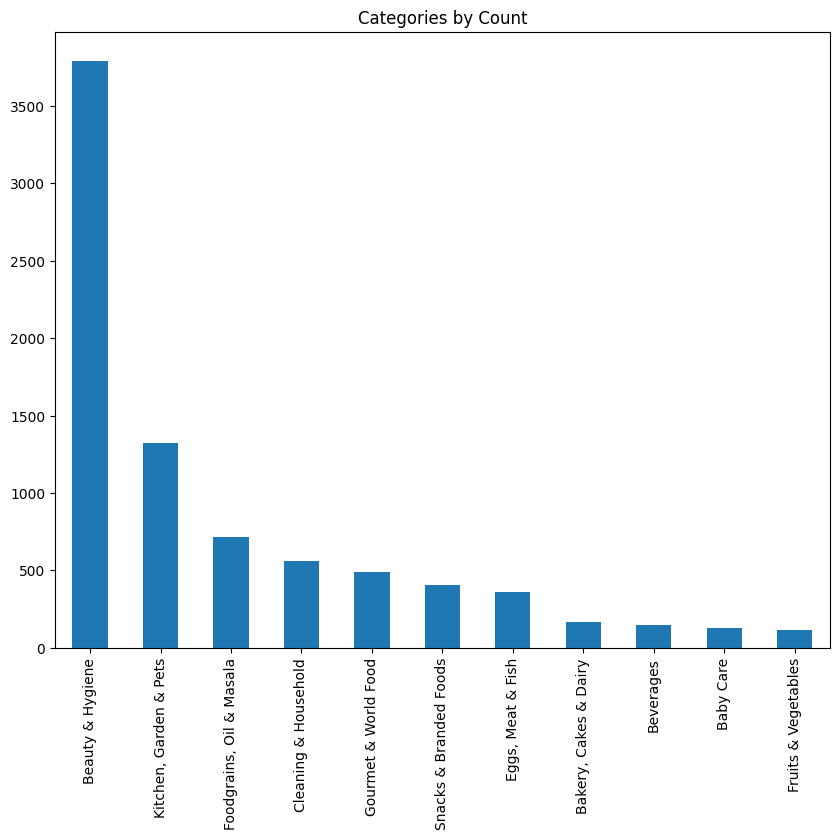

In [19]:
df_bigbasket["Category"].value_counts().plot(
    kind="bar", figsize=(10, 8), title="Categories by Count"
)

<Axes: title={'center': 'SubCategories by Count'}>

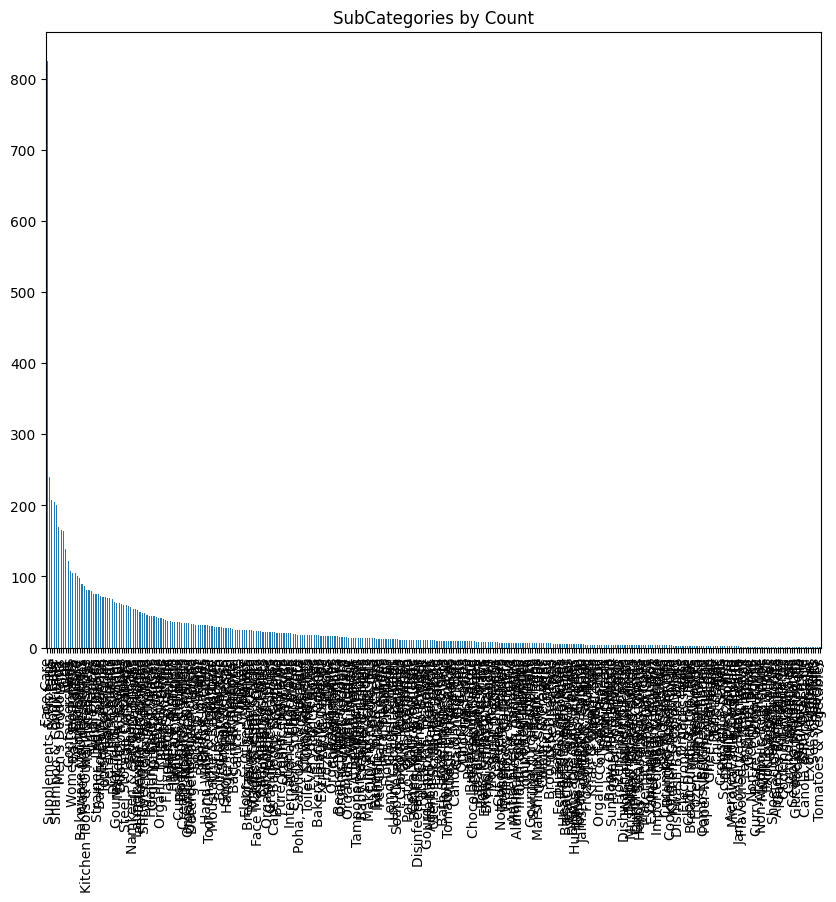

In [20]:
df_bigbasket["SubCategory"].value_counts().plot(
    kind="bar", figsize=(10, 8), title="SubCategories by Count"
)

In [22]:
df_bigbasket["SubCategory"].nunique()

334

## SubCategory clusters (interactive)

In [ ]:
import numpy as np
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE

N_CLUSTERS = 15  # tweak this: fewer = coarser groups

# One "document" per SubCategory: all its product names + brands
sub = (
    df_bigbasket.assign(text=df_bigbasket["ProductName"] + " " + df_bigbasket["Brand"])
    .groupby("SubCategory")
    .agg(
        Category=("Category", lambda s: s.mode().iat[0]),
        n_products=("ProductName", "size"),
        median_price=("DiscountPrice", "median"),
        top_products=("ProductName", lambda s: "<br>".join(s.value_counts().index[:4])),
        top_brands=("Brand", lambda s: ", ".join(s.value_counts().index[:3])),
        text=("text", " ".join),
    )
    .reset_index()
)

X = TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True).fit_transform(sub["text"])
Xs = TruncatedSVD(n_components=30, random_state=0).fit_transform(X)
Xs /= np.linalg.norm(Xs, axis=1, keepdims=True) + 1e-9

sub["cluster"] = KMeans(N_CLUSTERS, n_init=10, random_state=0).fit_predict(Xs)
xy = TSNE(perplexity=20, metric="cosine", init="pca", random_state=0).fit_transform(Xs)
sub["x"], sub["y"] = xy[:, 0], xy[:, 1]

# Name each cluster after its most common Category + biggest subcategory
sub["cluster_name"] = sub["cluster"].map(
    sub.groupby("cluster").apply(
        lambda g: (
            f"{g['Category'].mode().iat[0]} / {g.loc[g['n_products'].idxmax(), 'SubCategory']}"
        )
    )
)

In [ ]:
fig = px.scatter(
    sub,
    x="x",
    y="y",
    color="cluster_name",
    size="n_products",
    size_max=28,
    hover_name="SubCategory",
    hover_data={
        "x": False,
        "y": False,
        "cluster_name": True,
        "Category": True,
        "n_products": True,
        "median_price": ":.0f",
        "top_brands": True,
        "top_products": True,
    },
    title="BigBasket SubCategories: clustered by product-name similarity",
    width=1100,
    height=750,
)
fig.update_layout(xaxis_visible=False, yaxis_visible=False, legend_title_text="Cluster")
fig.show()

In [ ]:
# Quick table view of each cluster
(
    sub.groupby("cluster_name")
    .agg(
        n_subcats=("SubCategory", "size"),
        n_products=("n_products", "sum"),
        members=("SubCategory", lambda s: ", ".join(s)),
    )
    .sort_values("n_products", ascending=False)
)